In [1]:
import pandas as pd
df = pd.read_csv("../../course_assignments/homework8/state_data.csv")

In [5]:
print(df.shape)

(52, 4)


In [6]:
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

Rows: 52, Columns: 4


In [7]:
df.head()

,state,latitude,longitude,name
0,AK,63.588753,-154.493062,Alaska
1,AL,32.318231,-86.902298,Alabama
2,AR,35.201050,-91.831833,Arkansas
3,AZ,34.048928,-111.093731,Arizona
4,CA,36.778261,-119.417932,California


In [8]:
df.tail()

,state,latitude,longitude,name
47,VT,44.558803,-72.577841,Vermont
48,WA,47.751074,-120.740139,Washington
49,WI,43.784440,-88.787868,Wisconsin
50,WV,38.597626,-80.454903,West Virginia
51,WY,43.075968,-107.290284,Wyoming


In [ ]:
What the columns represent:
    
state is the two-letter postal abbreviation, such as AK.
latitude is the latitude of the state’s approximate geographic center, in degrees north.
longitude is the longitude of that same point, in degrees. It’s negative because the U.S. is west of the prime meridian.
name is the full name of the state or territory.
    
First state: Alaska (AK). The rows are in alphabetical order by postal code.

Last state: Wyoming (WY).
    
Total entries: 52 rows. The shape is (52, 4), so 52 rows and 4 columns.
    
Why more than 50: The dataset includes Washington, D.C. and Puerto Rico in addition to the 50 states.

In [10]:
median_lon = df["longitude"].median()
median_lat = df["latitude"].median()

print(f"Median longitude: {median_lon}")
print(f"Median latitude: {median_lat}")

df["lat_distance"] = (df["latitude"] - median_lat).abs()
df["lon_distance"] = (df["longitude"] - median_lon).abs()

print(df.shape)

Median longitude: -89.093198
Median latitude: 39.4355155
(52, 6)


In [ ]:
closest_lat = df.loc[df["lat_distance"].idxmin()]
farthest_lat = df.loc[df["lat_distance"].idxmax()]
closest_lon = df.loc[df["lon_distance"].idxmin()]
farthest_lon = df.loc[df["lon_distance"].idxmax()]

print(f"Closest to the median latitude: {closest_lat['name']} by {closest_lat['lat_distance']:.2f}")
print(f"Farthest from median latitude: {farthest_lat['name']} by {farthest_lat['lat_distance']:.2f}")
print(f"Closest to teh median longitude: {closest_lon['name']} by {closest_lon['lon_distance']:.2f}")
print(f"Farthest from median longitude: {farthest_lon['name']} by {farthest_lon['lon_distance']:.2f}")

In [ ]:
# Find the 5 states farthest from the median latitude
top5 = df.nlargest(5, "lat_distance")
print(top5[["name", "lat_distance"]])

# Where I found it: in the search bar on the pandas site
# What it does: returns the n rows with the largest values in a column, sorted from largest to smallest
# When it's good: when finding outliers in a big dataset it runs faster than writing your own version of a search.


In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

df2 = sns.load_dataset("diamonds")
print(df2)

       carat        cut color clarity  depth  table  price     x     y     z
0       0.23      Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1       0.21    Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2       0.23       Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3       0.29    Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4       0.31       Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75
...      ...        ...   ...     ...    ...    ...    ...   ...   ...   ...
53935   0.72      Ideal     D     SI1   60.8   57.0   2757  5.75  5.76  3.50
53936   0.72       Good     D     SI1   63.1   55.0   2757  5.69  5.75  3.61
53937   0.70  Very Good     D     SI1   62.8   60.0   2757  5.66  5.68  3.56
53938   0.86    Premium     H     SI2   61.0   58.0   2757  6.15  6.12  3.74
53939   0.75      Ideal     D     SI2   62.2   55.0   2757  5.83  5.87  3.64

[53940 rows x 10 columns]


In [16]:
print(df2.shape) # 53940 rows, 10 columns

# carat: weight of the diamond
# cut: cut quality
# color: color grade of the diamond (D best, J worst)
# clarity: how perfect (or imperfect) the diamond is
# depth: total depth (top to bottom) as a percentage
# table: width of the top face relative to the widest point, as a percentage
# price: cost in USD
# x: length (front to back distance of diamond)
# y: width (side to side distance of diamond)
# z: depth (top to bottom distance of diamond)
df2.head()

(53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [17]:
df2.tail()

,carat,cut,color,clarity,depth,table,price,x,y,z
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74
53939,0.75,Ideal,D,SI2,62.2,55.0,2757,5.83,5.87,3.64


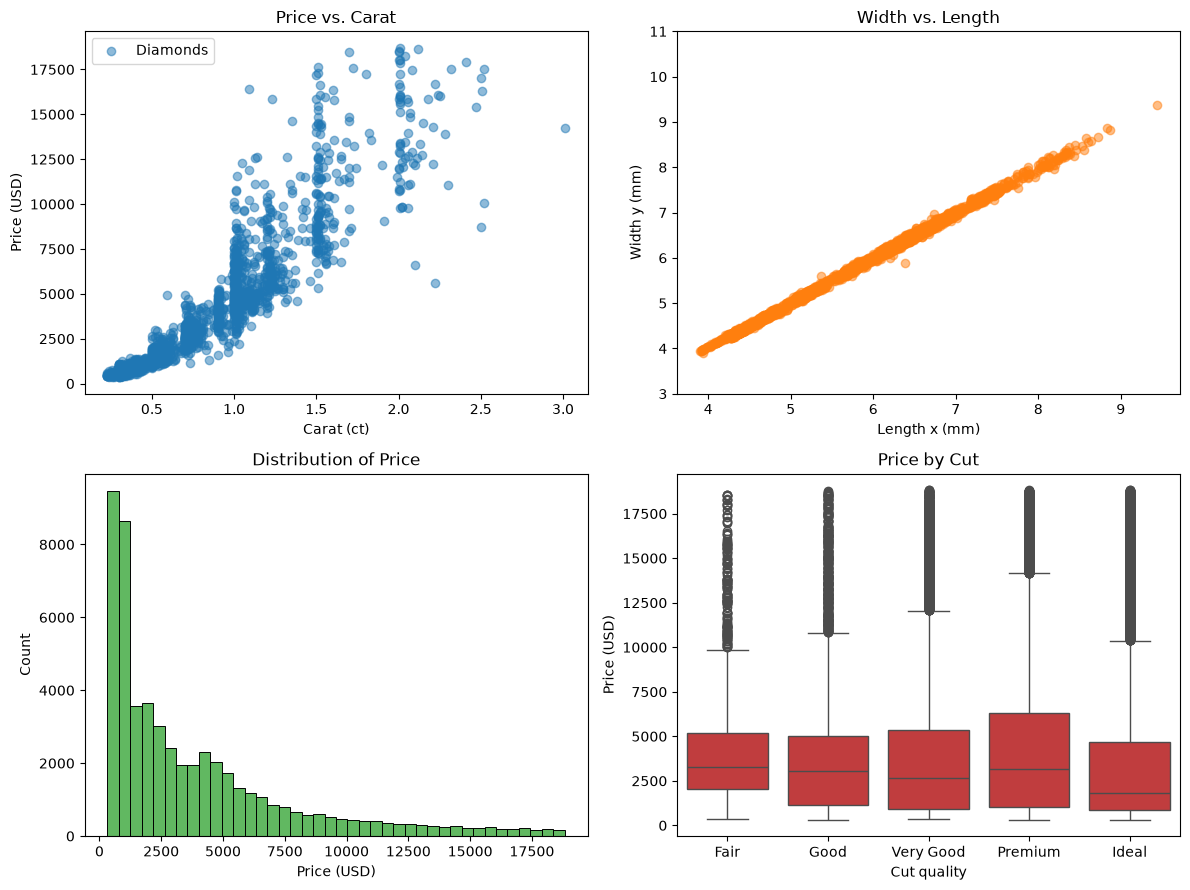

In [20]:
sample = df2.sample(2000, random_state=0)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Top left: carat vs price
axes[0, 0].scatter(sample["carat"], sample["price"], color="tab:blue", alpha=0.5, label="Diamonds")
axes[0, 0].set_title("Price vs. Carat")
axes[0, 0].set_xlabel("Carat (ct)")
axes[0, 0].set_ylabel("Price (USD)")
axes[0, 0].legend()

# Top right: length vs width (different columns)
axes[0, 1].scatter(sample["x"], sample["y"], color="tab:orange", alpha=0.5)
axes[0, 1].set_title("Width vs. Length")
axes[0, 1].set_xlabel("Length x (mm)")
axes[0, 1].set_ylabel("Width y (mm)")
axes[0, 1].set_ylim(3, 11)

# Bottom left: histogram
sns.histplot(df2["price"], bins=40, color="tab:green", ax=axes[1, 0])
axes[1, 0].set_title("Distribution of Price")
axes[1, 0].set_xlabel("Price (USD)")
axes[1, 0].set_ylabel("Count")

# Bottom right: boxplot
# 
sns.boxplot(x="cut", y="price", data=df2, color="tab:red", ax=axes[1, 1],
            order=["Fair", "Good", "Very Good", "Premium", "Ideal"])
axes[1, 1].set_title("Price by Cut")
axes[1, 1].set_xlabel("Cut quality")
axes[1, 1].set_ylabel("Price (USD)")

plt.tight_layout()
plt.show()

In [ ]:
# Top left (price vs. carat): I compared a diamond’s weight to its price because carat is the most obvious feature that should affect value. The plot shows that price rises with carat, but not in a straight line. Heavier diamonds are worth much more per carat, and prices vary widely among stones of similar size.

# Top right (length vs. width): I chose these two columns because they’re both physical measurements of the stone. The points fall almost on a line, which tells me diamonds are cut nearly round, so length and width are almost equal. A few points are far off the line, and those look like data errors.

# Bottom left (price histogram): I used price because it’s the main thing a buyer cares about. Most diamonds are fairly cheap, and a small number are very expensive, so the distribution is skewed to the right. That means the average price is pulled up by the few expensive stones.

# Bottom right (price by cut): I used the boxplot to see whether a better cut means a higher price. It doesn’t. Ideal-cut diamonds are not the most expensive, probably because they tend to be smaller, and carat affects price more than cut does.